In [1]:
import wandb
import sys
import matplotlib.pyplot as plt
import scprep
import pandas as pd
sys.path.append('../hypgs/models')
from omegaconf import OmegaConf
from train_ae import load_data, make_model
import numpy as np
import os
import glob
import scanpy as sc
os.chdir('/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/hypergraph_scattering/hypgs/models')

In [2]:
# Initialize wandb (replace 'your_entity' and 'your_project' with your specific details)
wandb.login()
api = wandb.Api()

# Specify your entity, project, and sweep ID
entity = "xingzhis"
project = "dmae"
sweep_id = 'zrx90d9u'

# Fetch the sweep
sweep = api.sweep(f"{entity}/{project}/{sweep_id}")
run_ids = [run.id for run in sweep.runs]
folder_path = "wandb/"


Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: xingzhis. Use `wandb login --relogin` to force relogin


In [3]:
# Initialize an empty list to store run data
runs_data = []

# Iterate through each run in the sweep
for run in sweep.runs:
    # Extract metrics and configs
    metrics = run.summary._json_dict
    configs = run.config
    
    # Combine metrics and configs, and add run ID
    combined_data = {**metrics, **configs, "run_id": run.id}
    
    # Append the combined data to the list
    runs_data.append(combined_data)

# Create a DataFrame from the runs data
df = pd.DataFrame(runs_data)

In [4]:
df_logpdist_recon = df.iloc[[i for i in df.index if df['model.dist_contr_recon_weights'][i] == [0, 0, 1]],:]

In [5]:
df_logpdist_recon['data.name']

2     H21.33.028.CX28.MTG.02.007.1.01.01
5     H21.33.023.Cx26.MTG.02.007.1.03.05
7     H20.33.044.Cx26.MTG.02.007.1.01.04
14    H21.33.019.Cx30.MTG.02.007.5.01.01
15     H21.33.022.Cx26.MTG.02.007.2.M.04
16    H20.33.001.CX28.MTG.02.007.1.02.02
Name: data.name, dtype: object

In [6]:
import torch
res = []
# run = [run for run in sweep.runs if run.id == 'bae5whsi'][0]
for idx in df_logpdist_recon['run_id']:
    run = [run for run in sweep.runs if run.id == idx][0]
    cfg = OmegaConf.create(run.config)
    folder_path = "wandb/"
    folder_list = glob.glob(f"{folder_path}*{run.id}*")
    ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
    ckpt_path = ckpt_files[0]
    trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
    emb_dim = phate_coords.shape[1]
    data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
    data = np.load(data_path, allow_pickle=True)
    dist_std = np.std(data['dist'].flatten())
    model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
    model.eval()
    x_all = torch.tensor(data['data'][data['is_train']]).float()
    x_pred, z_pred = model(x_all)
    x_pred = x_pred.detach().cpu().numpy()
    z_pred = z_pred.detach().cpu().numpy()
    section = cfg.data.name
    classes = np.load(f'../../data/hgsae/{section}_label.npy', allow_pickle=True)
    classes = classes[data['is_train']]
    res_dict = dict(
        z_pred=z_pred,
        classes=classes,
        section=section,
    )
    res.append(res_dict)
# scprep.plot.scatter2d(z_pred, title=section, ticks=False,c=classes, figsize=(10,10), s=50)

In [7]:
section_df = pd.read_csv('/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/sea_ad/data/hypergraphae/braak.csv')

In [8]:
section_dict = {section: braak for section, braak in zip(section_df['Section'], section_df['Braak'])}

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be

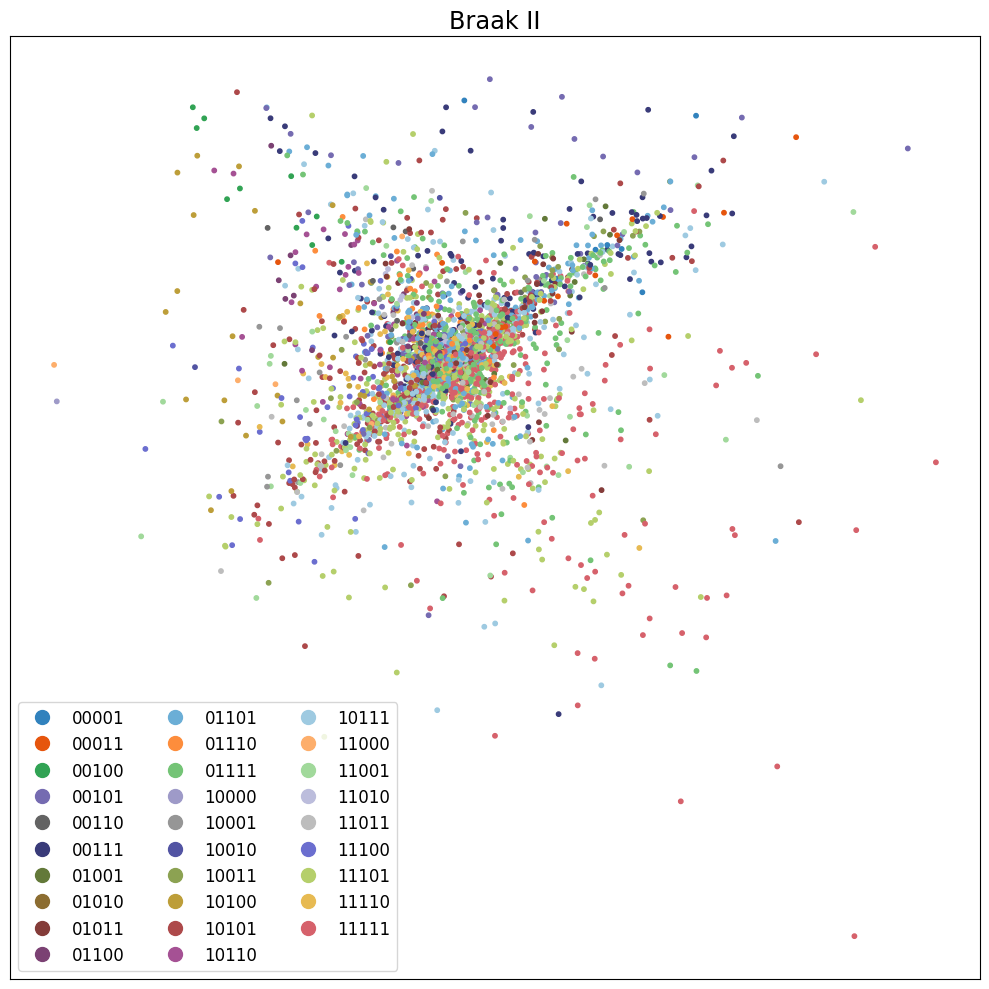

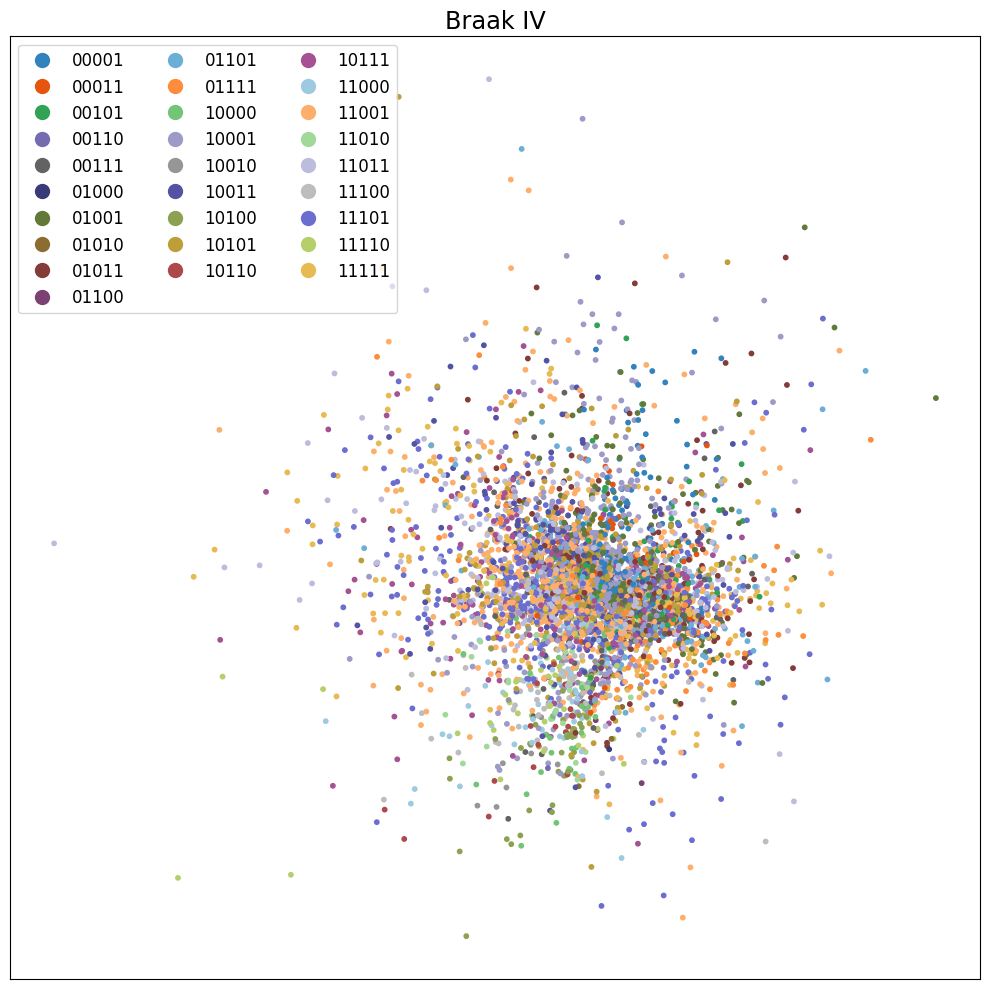

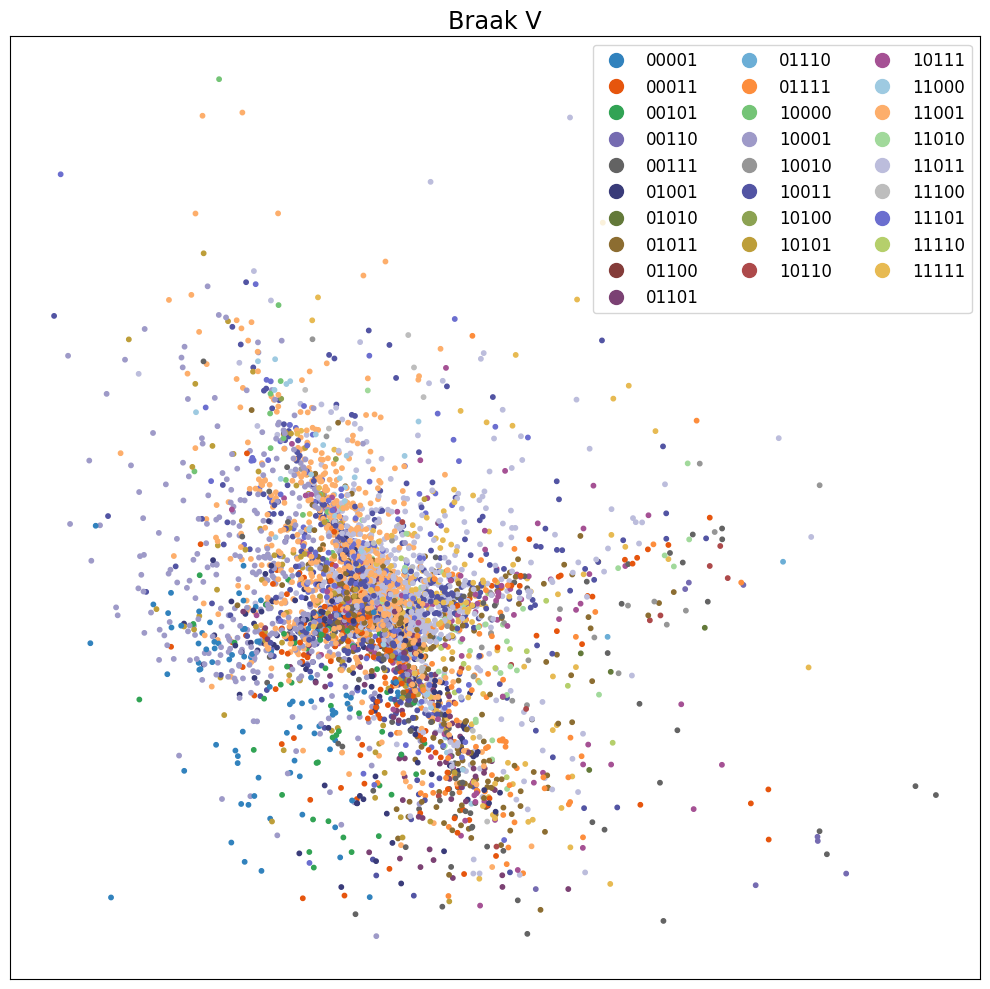

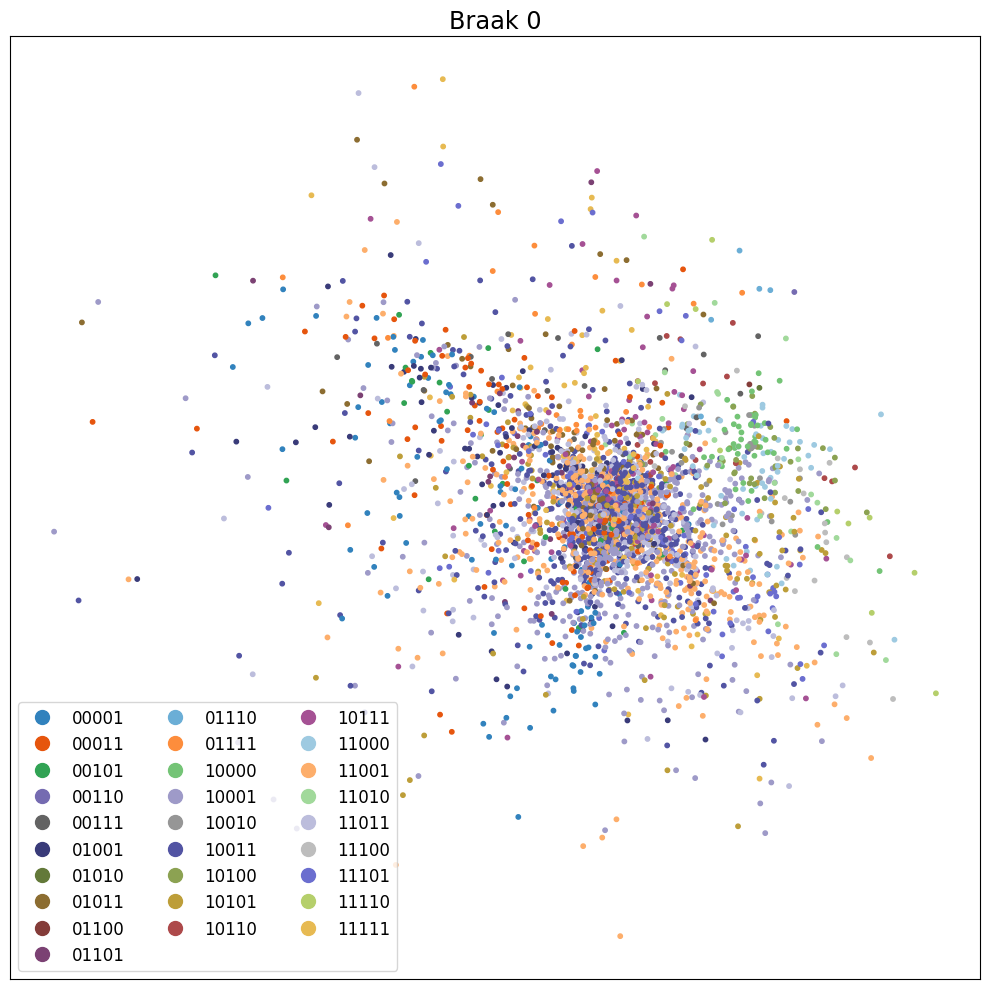

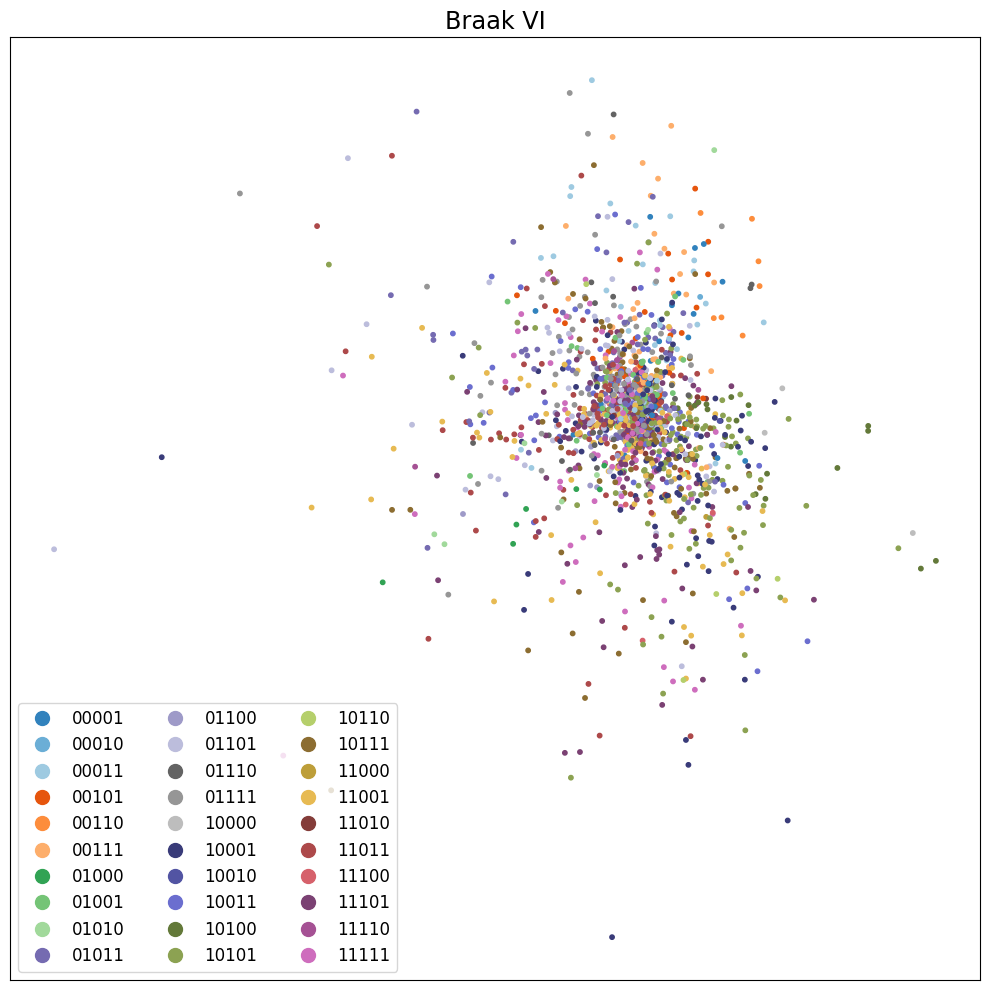

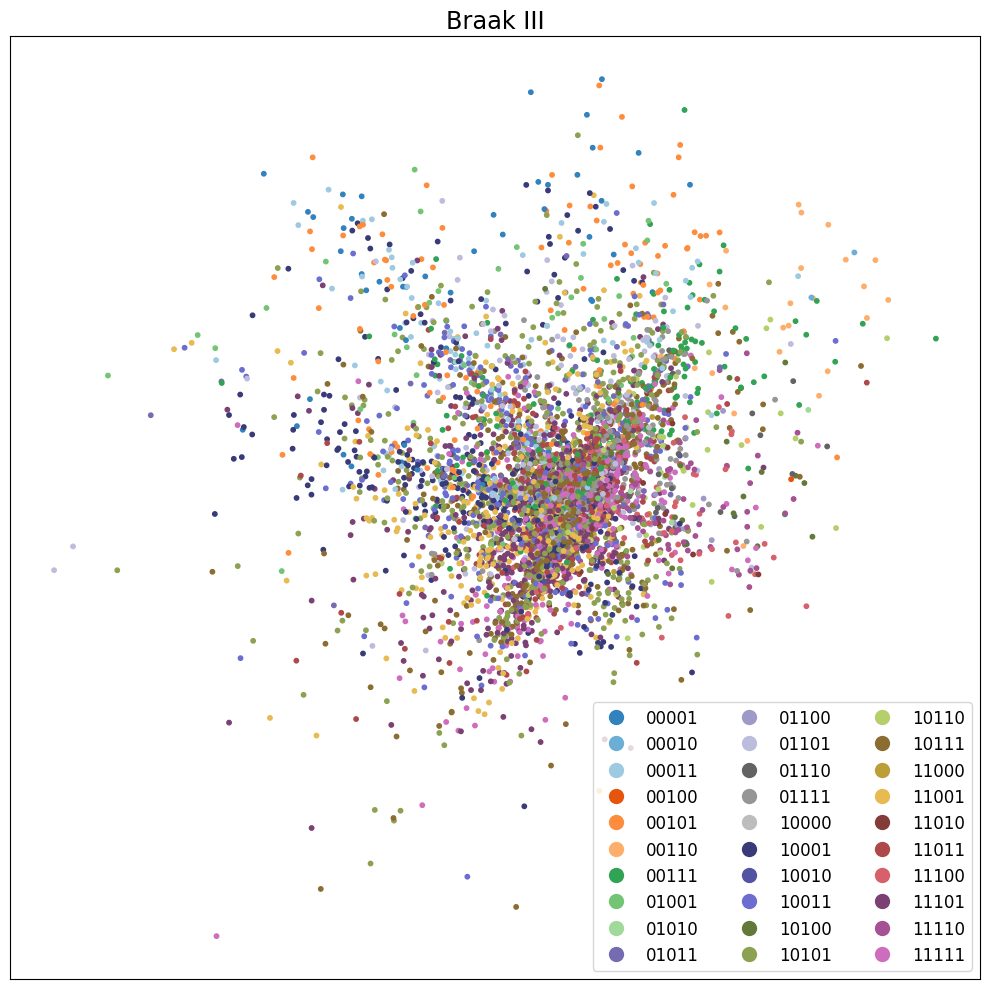

In [9]:
for res_dict in res:
    z_pred = res_dict['z_pred']
    classes = res_dict['classes']
    section = res_dict['section']
    braak = section_dict[section]
    scprep.plot.scatter2d(z_pred, title=braak, ticks=False,c=classes, figsize=(10,10), s=10)

In [10]:
res_dict_by_braak = {}
for res_dict in res:
    braak = section_dict[res_dict['section']]
    res_dict_by_braak[braak] = res_dict

In [11]:
res_dict_by_braak.keys()

dict_keys(['Braak II', 'Braak IV', 'Braak V', 'Braak 0', 'Braak VI', 'Braak III'])

In [12]:
braak_list = ['Braak 0', 'Braak II', 'Braak III', 'Braak IV', 'Braak V', 'Braak VI']

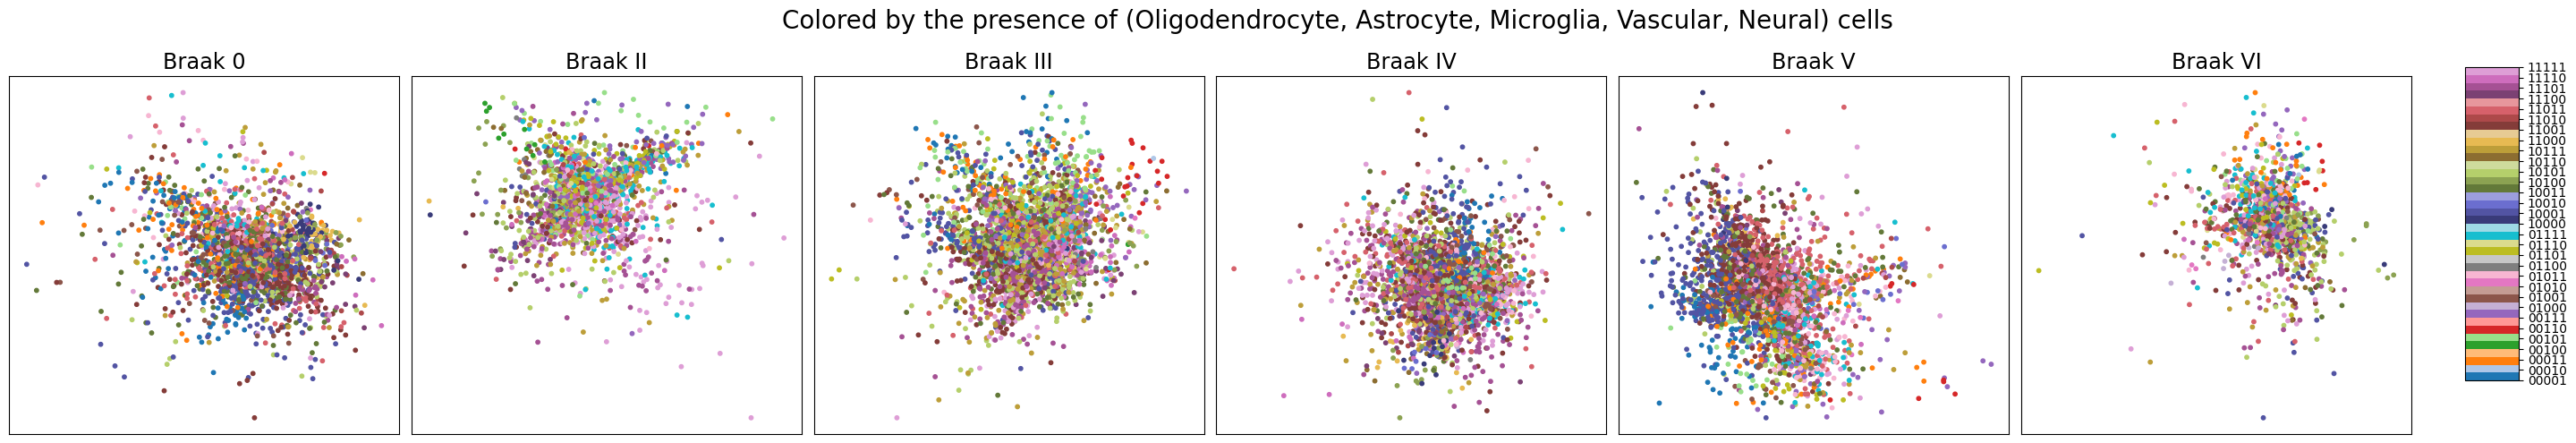

In [13]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scprep
import numpy as np

# Assuming res is your list of dictionaries and section_dict is defined

# Create a figure with a 2x3 grid of subplots
fig, axes = plt.subplots(1, 6, figsize=(30, 5))  # Adjusted for a 1x6 layout
axes = axes.flatten() # Flatten the 2D array of axes to easily iterate over it
plt.suptitle('Colored by the presence of (Oligodendrocyte, Astrocyte, Microglia, Vascular, Neural) cells', fontsize=20)

# Combine tab20 and tab20b colormaps to have 40 distinct colors
tab20 = plt.cm.tab20(np.linspace(0, 1, 20))
tab20b = plt.cm.tab20b(np.linspace(0, 1, 20))
colors = np.vstack((tab20, tab20b))
custom_cmap = mcolors.ListedColormap(colors)

# Generate a unified colormap. First, find all unique classes across all res_dicts
unique_classes = sorted(set(cls for res_dict in res for cls in res_dict['classes']))
# Create a dictionary to map each class to a unique integer
class_to_int = {cls: i for i, cls in enumerate(unique_classes)}

# Iterate over each res_dict and its corresponding subplot axis
for ax, braak in zip(axes, braak_list):
    res_dict = res_dict_by_braak[braak]
    z_pred = res_dict['z_pred']
    classes = res_dict['classes']
    section = res_dict['section']
    braak = section_dict[section]

    # Map classes to integers using the class_to_int mapping
    classes_int = np.array([class_to_int[cls] for cls in classes])

    # Plot using scprep with the specified axis (ax) and the unified discrete colormap
    scprep.plot.scatter2d(z_pred, title=braak, ticks=False, c=classes_int,
                          cmap=custom_cmap, figsize=(10, 10), s=10, ax=ax, legend=False)

# Adjust layout for better spacing
plt.tight_layout()

# Show unified colorbar with class labels
# Create a new axis for the colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# Create a colorbar with the mapping from classes_int to colors
sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=plt.Normalize(vmin=0, vmax=len(unique_classes)-1))
# Fake up the array of the scalar mappable. _A is a matplotlib artifact
sm._A = []
# Add the colorbar to the figure
plt.colorbar(sm, cax=cbar_ax, ticks=np.arange(len(unique_classes)))
# Set the tick labels to the unique classes
cbar_ax.set_yticklabels(unique_classes)

# Adjust figure to make room for the colorbar
plt.subplots_adjust(right=0.9)

plt.show()


In [14]:
def coarsen_classes(cls):
    assert len(cls) == 5
    return cls[-2:]

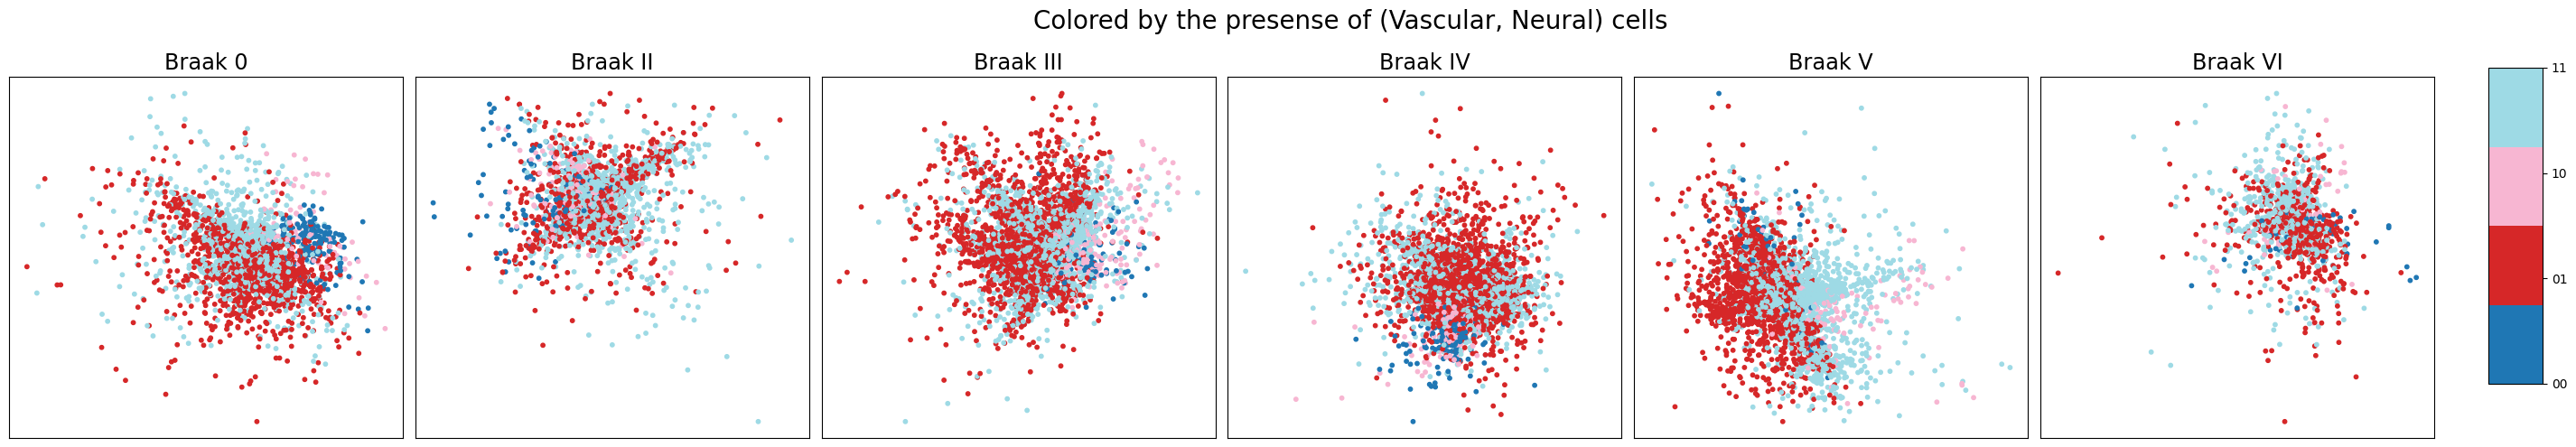

In [15]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scprep
import numpy as np

# Assuming res is your list of dictionaries and section_dict is defined

# Create a figure with a 2x3 grid of subplots
fig, axes = plt.subplots(1, 6, figsize=(30, 5))  # Adjusted for a 1x6 layout
axes = axes.flatten() # Flatten the 2D array of axes to easily iterate over it
plt.suptitle('Colored by the presense of (Vascular, Neural) cells', fontsize=20)

# Generate a unified colormap. First, find all unique classes across all res_dicts
unique_classes = sorted(set(clss[-2:] for res_dict in res for clss in res_dict['classes']))
# Create a dictionary to map each class to a unique integer
class_to_int = {clss: i for i, clss in enumerate(unique_classes)}

# Combine tab20 and tab20b colormaps to have 40 distinct colors
tab20 = plt.cm.tab20(np.linspace(0, 1, len(unique_classes)))
# tab20b = plt.cm.tab20b(np.linspace(0, 1, 20))
# colors = np.vstack((tab20, tab20b))
colors = tab20
custom_cmap = mcolors.ListedColormap(colors)


# Iterate over each res_dict and its corresponding subplot axis
for ax, braak in zip(axes, braak_list):
    res_dict = res_dict_by_braak[braak]
    z_pred = res_dict['z_pred']
    classes = res_dict['classes']
    classes = [clss[-2:] for clss in classes]
    section = res_dict['section']
    braak = section_dict[section]

    # Map classes to integers using the class_to_int mapping
    classes_int = np.array([class_to_int[clss] for clss in classes])

    # Plot using scprep with the specified axis (ax) and the unified discrete colormap
    scprep.plot.scatter2d(z_pred, title=braak, ticks=False, c=classes_int,
                          cmap=custom_cmap, figsize=(10, 10), s=10, ax=ax, legend=False)

# Adjust layout for better spacing
plt.tight_layout()

# Show unified colorbar with class labels
# Create a new axis for the colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# Create a colorbar with the mapping from classes_int to colors
sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=plt.Normalize(vmin=0, vmax=len(unique_classes)-1))
# Fake up the array of the scalar mappable. _A is a matplotlib artifact
sm._A = []
# Add the colorbar to the figure
plt.colorbar(sm, cax=cbar_ax, ticks=np.arange(len(unique_classes)))
# Set the tick labels to the unique classes
cbar_ax.set_yticklabels(unique_classes)

# Adjust figure to make room for the colorbar
plt.subplots_adjust(right=0.9)

plt.show()


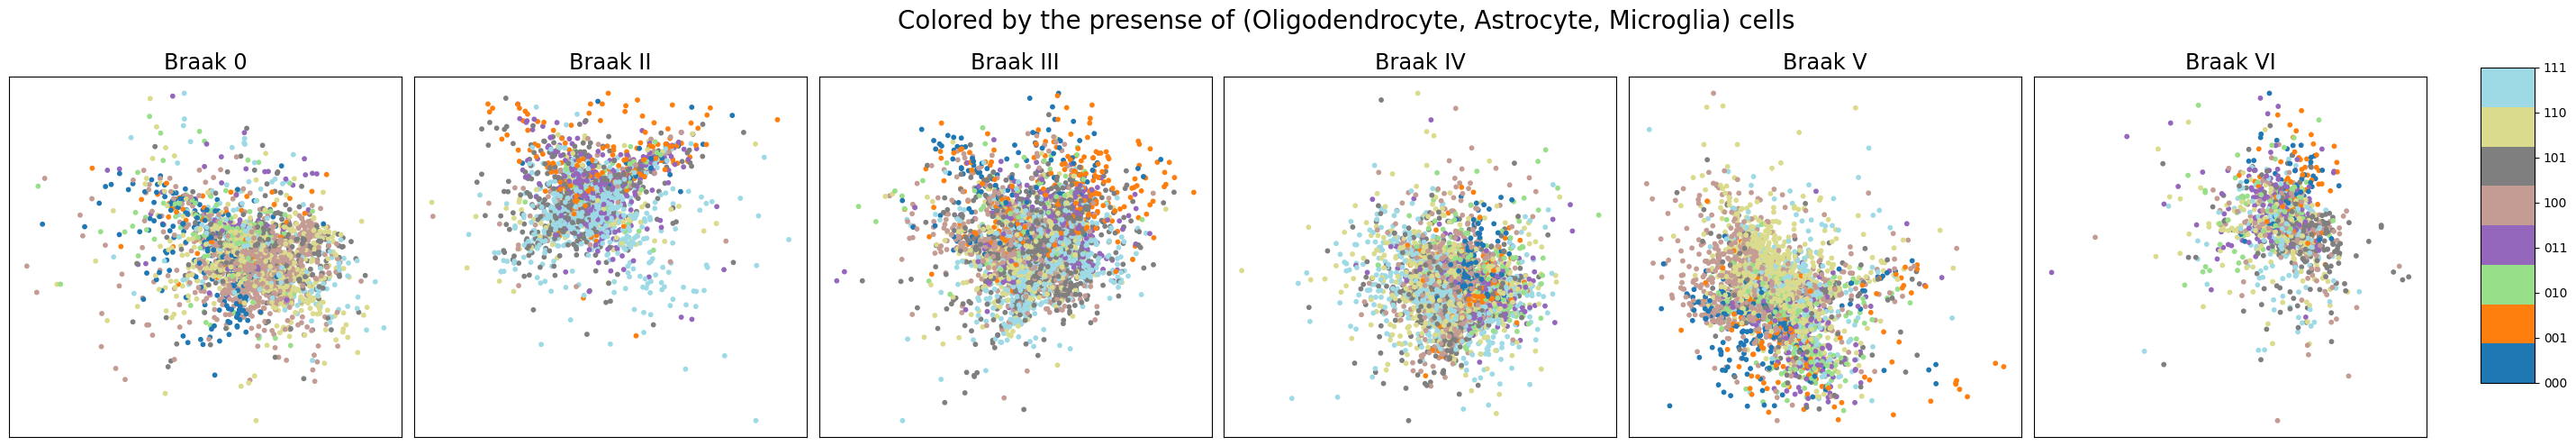

In [16]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scprep
import numpy as np

# Assuming res is your list of dictionaries and section_dict is defined

# Create a figure with a 2x3 grid of subplots
fig, axes = plt.subplots(1, 6, figsize=(30, 5))  # Adjusted for a 1x6 layout
axes = axes.flatten() # Flatten the 2D array of axes to easily iterate over it
plt.suptitle('Colored by the presense of (Oligodendrocyte, Astrocyte, Microglia) cells', fontsize=20)


# Generate a unified colormap. First, find all unique classes across all res_dicts
unique_classes = sorted(set(clss[:-2] for res_dict in res for clss in res_dict['classes']))
# Create a dictionary to map each class to a unique integer
class_to_int = {clss: i for i, clss in enumerate(unique_classes)}

# Combine tab20 and tab20b colormaps to have 40 distinct colors
tab20 = plt.cm.tab20(np.linspace(0, 1, len(unique_classes)))
# tab20b = plt.cm.tab20b(np.linspace(0, 1, 20))
# colors = np.vstack((tab20, tab20b))
colors = tab20
custom_cmap = mcolors.ListedColormap(colors)


# Iterate over each res_dict and its corresponding subplot axis
for ax, braak in zip(axes, braak_list):
    res_dict = res_dict_by_braak[braak]
    z_pred = res_dict['z_pred']
    classes = res_dict['classes']
    classes = [clss[:-2] for clss in classes]
    section = res_dict['section']
    braak = section_dict[section]

    # Map classes to integers using the class_to_int mapping
    classes_int = np.array([class_to_int[clss] for clss in classes])

    # Plot using scprep with the specified axis (ax) and the unified discrete colormap
    scprep.plot.scatter2d(z_pred, title=braak, ticks=False, c=classes_int,
                          cmap=custom_cmap, figsize=(10, 10), s=10, ax=ax, legend=False)

# Adjust layout for better spacing
plt.tight_layout()

# Show unified colorbar with class labels
# Create a new axis for the colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# Create a colorbar with the mapping from classes_int to colors
sm = plt.cm.ScalarMappable(cmap=custom_cmap, norm=plt.Normalize(vmin=0, vmax=len(unique_classes)-1))
# Fake up the array of the scalar mappable. _A is a matplotlib artifact
sm._A = []
# Add the colorbar to the figure
plt.colorbar(sm, cax=cbar_ax, ticks=np.arange(len(unique_classes)))
# Set the tick labels to the unique classes
cbar_ax.set_yticklabels(unique_classes)

# Adjust figure to make room for the colorbar
plt.subplots_adjust(right=0.9)

plt.show()


In [17]:
section_df

,Donor ID,Sex,Gender,Age at Death,Race (choice=White),Race (choice=Black/ African American),Race (choice=Asian),Race (choice=American Indian/ Alaska Native),Race (choice=Native Hawaiian or Pacific Islander),Race (choice=Unknown or unreported),...,Section,Genes detected,Number of spots,Depth from pia,Normalized depth from pia,Continuous Pseudo-progression Score,Layer annotation,Merscope,Cell volume,Used in analysis
0,H21.33.001,Male,Male,80,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H20.33.001.CX28.MTG.02.007.1.02.02,96.0,573.0,1886.388173,0.315663,0.149616,L2/3,early merscope,2469.551283,1
1,H20.33.044,Male,Male,81,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H20.33.044.Cx26.MTG.02.007.1.01.04,21.0,49.0,2979.073541,0.634141,0.355632,L5,early merscope,873.221928,1
2,H21.33.023,Male,Male,90+,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H21.33.023.Cx26.MTG.02.007.1.03.05,75.0,376.0,2101.403996,0.521880,0.296555,L4,early merscope,1509.687082,1
3,H21.33.019,Male,Male,75,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H21.33.019.Cx30.MTG.02.007.5.01.01,28.0,50.0,1059.758726,0.301411,0.517476,L2/3,early merscope,572.222831,1
4,H21.33.022,Female,Female,82,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H21.33.022.Cx26.MTG.02.007.2.M.04,16.0,39.0,2128.522184,0.901600,0.739924,L6,early merscope,1452.786392,1
5,H21.33.028,Male,Male,72,Checked,Unchecked,Unchecked,Unchecked,Unchecked,Unchecked,...,H21.33.028.CX28.MTG.02.007.1.01.01,50.0,148.0,209.288009,0.042926,0.300177,L1,Madison25,1712.451973,1
